In [ ]:
from datetime import datetime
import os
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

In [12]:


# Dataset directory
data_dir = Path(r"E:\github\c_online_retail_II")

# Find Excel files in the dataset directory
excel_files = sorted(
    list(data_dir.glob("*.xlsx")) +
    list(data_dir.glob("*.xls"))
)

if not excel_files:
    raise FileNotFoundError(
        f"No Excel file found in: {data_dir}\n"
        "Check the folder path and dataset file."
    )

if len(excel_files) > 1:
    print("Excel files found:")
    for i, file in enumerate(excel_files, start=1):
        print(f"{i}. {file.name}")

    raise ValueError(
        "Multiple Excel files found. "
        "Please select the correct dataset explicitly."
    )

excel_file = excel_files[0]

df = pd.read_excel(excel_file, engine="openpyxl")

print(f"Dataset loaded: {excel_file.name}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded: online_retail_II.xlsx
Rows: 525,461
Columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:

required_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]

missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = df.copy()

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

print("Missing values in required columns:")
print(df[required_columns].isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Invalid invoice dates:", df["InvoiceDate"].isna().sum())

tx_uk = df.loc[
    df["Country"].eq("United Kingdom")
].copy()

tx_uk = tx_uk.reset_index(drop=True)

print("\nUK transactions:", f"{len(tx_uk):,}")
print("Unique customers:", tx_uk["Customer ID"].nunique())


Missing values in required columns:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Duplicate rows: 6865
Invalid invoice dates: 0

UK transactions: 485,852
Unique customers: 4035


In [5]:

df = df.copy()

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)
df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

print("Original rows:", len(df))
print("Missing customer IDs:", df["Customer ID"].isna().sum())
print("Invalid dates:", df["InvoiceDate"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.dropna(
    subset=["Customer ID", "InvoiceDate", "Invoice", "Quantity", "Price"]
).copy()

df["Customer ID"] = df["Customer ID"].astype("int64")

df["Invoice"] = df["Invoice"].astype(str).str.strip()

df["Country"] = df["Country"].astype("string").str.strip()

df["IsCancelled"] = df["Invoice"].str.upper().str.startswith("C")

df["Revenue"] = df["Quantity"] * df["Price"]

print("\nCancelled invoices:", df["IsCancelled"].sum())
print("Rows with zero or negative quantity:", (df["Quantity"] <= 0).sum())
print("Rows with zero or negative price:", (df["Price"] <= 0).sum())

tx_uk = df.loc[
    (df["Country"] == "United Kingdom") &
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

tx_uk = tx_uk.reset_index(drop=True)

print("\nRows after filtering:", len(tx_uk))
print("Unique customers:", tx_uk["Customer ID"].nunique())
print("Date range:", tx_uk["InvoiceDate"].min(), "to", tx_uk["InvoiceDate"].max())


Original rows: 525461
Missing customer IDs: 107927
Invalid dates: 0
Duplicate rows: 6865

Cancelled invoices: 9839
Rows with zero or negative quantity: 9839
Rows with zero or negative price: 31

Rows after filtering: 370929
Unique customers: 3969
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00


In [6]:

train_start = pd.Timestamp("2010-03-01")
train_end = pd.Timestamp("2010-06-01")

target_start = pd.Timestamp("2010-06-01")
target_end = pd.Timestamp("2010-12-01")

tx_3m = tx_uk.loc[
    (tx_uk["InvoiceDate"] >= train_start) &
    (tx_uk["InvoiceDate"] < train_end)
].copy()

tx_6m = tx_uk.loc[
    (tx_uk["InvoiceDate"] >= target_start) &
    (tx_uk["InvoiceDate"] < target_end)
].copy()

if tx_3m.empty:
    raise ValueError("No transactions found in the training period.")

if tx_6m.empty:
    raise ValueError("No transactions found in the target period.")

print("Training period:")
print(tx_3m["InvoiceDate"].min(), "to", tx_3m["InvoiceDate"].max())
print("Training transactions:", len(tx_3m))

print("\nTarget period:")
print(tx_6m["InvoiceDate"].min(), "to", tx_6m["InvoiceDate"].max())
print("Target transactions:", len(tx_6m))


Training period:
2010-03-01 08:38:00 to 2010-05-30 15:58:00
Training transactions: 80422

Target period:
2010-06-01 09:02:00 to 2010-11-30 19:35:00
Target transactions: 207620


In [7]:

customer_ids = tx_3m["Customer ID"].drop_duplicates().sort_values()

tx_user = pd.DataFrame({
    "Customer ID": customer_ids.to_numpy()
})

print("Customers in training period:", len(tx_user))
print("Duplicate customer IDs:", tx_user["Customer ID"].duplicated().sum())

tx_user.head()


Customers in training period: 1901
Duplicate customer IDs: 0


,Customer ID
0,12346
1,12745
2,12747
3,12748
4,12820


In [8]:

snapshot_date = tx_3m["InvoiceDate"].max() + pd.Timedelta(days=1)

tx_max_purchase = (
    tx_3m.groupby("Customer ID")["InvoiceDate"]
    .max()
    .reset_index()
)

tx_max_purchase.columns = ["Customer ID", "MaxPurchaseDate"]

tx_max_purchase["Recency"] = (
    snapshot_date - tx_max_purchase["MaxPurchaseDate"]
).dt.days

tx_user = tx_user.merge(
    tx_max_purchase[["Customer ID", "Recency"]],
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

if tx_user["Recency"].isna().any():
    raise ValueError("Some customers do not have a valid Recency value.")

if (tx_user["Recency"] < 0).any():
    raise ValueError("Recency cannot be negative.")

print("Snapshot date:", snapshot_date)
print(tx_user["Recency"].describe())


Snapshot date: 2010-05-31 15:58:00
count    1901.000000
mean       36.140452
std        25.914734
min         1.000000
25%        13.000000
50%        32.000000
75%        59.000000
max        91.000000
Name: Recency, dtype: float64


In [9]:

from sklearn.cluster import KMeans

recency_values = tx_user[["Recency"]]

if recency_values["Recency"].nunique() < 4:
    raise ValueError("There are not enough unique Recency values for 4 clusters.")

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

tx_user["RecencyCluster"] = kmeans.fit_predict(recency_values)

print(tx_user.groupby("RecencyCluster")["Recency"].agg(
    ["count", "min", "mean", "max"]
))


                count  min       mean  max
RecencyCluster                            
0                 755    1  11.123179   22
1                 338   48  60.082840   70
2                 550   23  34.600000   47
3                 258   71  81.267442   91


In [10]:

def order_cluster(cluster_col, target_col, data, ascending=True):
    cluster_means = data.groupby(cluster_col)[target_col].mean()

    cluster_order = cluster_means.sort_values(
        ascending=ascending
    ).index

    cluster_map = {
        old_cluster: new_cluster
        for new_cluster, old_cluster in enumerate(cluster_order)
    }

    result = data.copy()
    result[cluster_col] = result[cluster_col].map(cluster_map)

    return result


In [11]:

tx_user = order_cluster(
    "RecencyCluster",
    "Recency",
    tx_user,
    ascending=False
)

recency_summary = (
    tx_user.groupby("RecencyCluster")["Recency"]
    .agg(["count", "mean", "min", "max"])
    .sort_values("RecencyCluster")
)

print(recency_summary)


                count       mean  min  max
RecencyCluster                            
0                 258  81.267442   71   91
1                 338  60.082840   48   70
2                 550  34.600000   23   47
3                 755  11.123179    1   22


In [13]:

tx_frequency = (
    tx_3m.groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index(name="Frequency")
)

tx_user = tx_user.drop(columns=["Frequency"], errors="ignore")

tx_user = tx_user.merge(
    tx_frequency,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

if tx_user["Frequency"].isna().any():
    raise ValueError("Some customers have missing Frequency values.")

if (tx_user["Frequency"] < 1).any():
    raise ValueError("Frequency must be at least 1.")

print(tx_user["Frequency"].describe())
print("Unique customers:", tx_user["Customer ID"].nunique())


count    1901.000000
mean        2.045239
std         2.606683
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        41.000000
Name: Frequency, dtype: float64
Unique customers: 1901


In [14]:

if tx_user["Frequency"].nunique() < 4:
    raise ValueError("Not enough unique Frequency values for clustering.")

kmeans_frequency = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

tx_user["FrequencyCluster"] = kmeans_frequency.fit_predict(
    tx_user[["Frequency"]]
)

tx_user = order_cluster(
    "FrequencyCluster",
    "Frequency",
    tx_user,
    ascending=True
)

frequency_summary = (
    tx_user.groupby("FrequencyCluster")["Frequency"]
    .agg(["count", "mean", "min", "max"])
    .sort_index()
)

print(frequency_summary)


                  count       mean  min  max
FrequencyCluster                            
0                  1521   1.269560    1    2
1                   356   4.137640    3   10
2                    21  17.619048   12   25
3                     3  38.000000   33   41


In [15]:

tx_3m = tx_3m.copy()

tx_3m["Revenue"] = tx_3m["Quantity"] * tx_3m["Price"]

tx_revenue = (
    tx_3m.groupby("Customer ID")["Revenue"]
    .sum()
    .reset_index()
)

tx_revenue.columns = ["Customer ID", "Revenue"]

tx_user = tx_user.drop(columns=["Revenue"], errors="ignore")

tx_user = tx_user.merge(
    tx_revenue,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

if tx_user["Revenue"].isna().any():
    raise ValueError("Some customers have missing Revenue values.")

if not np.isfinite(tx_user["Revenue"]).all():
    raise ValueError("Revenue contains infinite or invalid values.")

print(tx_user["Revenue"].describe())


count     1901.000000
mean       839.891569
std       2242.261693
min          4.250000
25%        228.450000
50%        405.000000
75%        800.750000
max      50985.910000
Name: Revenue, dtype: float64


In [16]:

if (tx_user["Revenue"] < 0).any():
    raise ValueError("Negative Revenue values must be reviewed before clustering.")

if tx_user["Revenue"].nunique() < 4:
    raise ValueError("Not enough unique Revenue values for clustering.")

revenue_log = np.log1p(tx_user[["Revenue"]])

kmeans_revenue = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

tx_user["RevenueCluster"] = kmeans_revenue.fit_predict(revenue_log)

tx_user = order_cluster(
    "RevenueCluster",
    "Revenue",
    tx_user,
    ascending=True
)

revenue_summary = (
    tx_user.groupby("RevenueCluster")["Revenue"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_index()
)

print(revenue_summary)


                count         mean    median      min       max
RevenueCluster                                                 
0                 392   128.687526   132.385     4.25    196.25
1                 781   346.490743   330.380   197.10    541.13
2                 572   926.823114   848.305   544.72   1703.15
3                 156  4778.437635  2605.435  1729.56  50985.91


In [17]:

feature_columns = [
    "Customer ID",
    "Recency",
    "Frequency",
    "Revenue",
    "RecencyCluster",
    "FrequencyCluster",
    "RevenueCluster"
]

print("Dataset shape:", tx_user.shape)
print("Duplicate customers:", tx_user["Customer ID"].duplicated().sum())
print("\nMissing values:")
print(tx_user[feature_columns].isna().sum())

print("\nCluster sizes:")
for column in ["RecencyCluster", "FrequencyCluster", "RevenueCluster"]:
    print(f"\n{column}")
    print(tx_user[column].value_counts().sort_index())

tx_user[feature_columns].head()


Dataset shape: (1901, 7)
Duplicate customers: 0

Missing values:
Customer ID         0
Recency             0
Frequency           0
Revenue             0
RecencyCluster      0
FrequencyCluster    0
RevenueCluster      0
dtype: int64

Cluster sizes:

RecencyCluster
RecencyCluster
0    258
1    338
2    550
3    755
Name: count, dtype: int64

FrequencyCluster
FrequencyCluster
0    1521
1     356
2      21
3       3
Name: count, dtype: int64

RevenueCluster
RevenueCluster
0    392
1    781
2    572
3    156
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Revenue,RecencyCluster,FrequencyCluster,RevenueCluster
0,12346,90,1,27.05,0,0,0
1,12745,16,1,456.92,3,0,1
2,12747,4,3,691.54,3,1,2
3,12748,5,19,2623.33,3,2,3
4,12820,6,1,228.45,3,0,1


In [18]:

cluster_columns = [
    "RecencyCluster",
    "FrequencyCluster",
    "RevenueCluster"
]

tx_user["OverallScore"] = tx_user[cluster_columns].sum(axis=1)

if not tx_user["OverallScore"].between(0, 9).all():
    raise ValueError("OverallScore must be between 0 and 9.")

print(tx_user["OverallScore"].value_counts().sort_index())
print("\nAverage metrics by score:")

print(
    tx_user.groupby("OverallScore")[
        ["Recency", "Frequency", "Revenue"]
    ].mean().round(2)
)


OverallScore
0     91
1    214
2    310
3    397
4    382
5    223
6    178
7     84
8     19
9      3
Name: count, dtype: int64

Average metrics by score:
              Recency  Frequency   Revenue
OverallScore                              
0               81.99       1.04    124.17
1               72.50       1.07    247.99
2               54.64       1.12    332.35
3               33.43       1.26    383.89
4               22.34       1.55    562.43
5               17.77       2.27    956.58
6               11.92       3.94   1402.13
7                9.48       5.67   3701.14
8                4.79      17.21  11155.16
9                4.67      38.00  25414.80


In [19]:

score_summary = (
    tx_user.groupby("OverallScore")
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgRevenue=("Revenue", "mean"),
        MedianRevenue=("Revenue", "median")
    )
    .round(2)
)

score_summary


,CustomerCount,AvgRecency,AvgFrequency,AvgRevenue,MedianRevenue
OverallScore,,,,,
0,91,81.99,1.04,124.17,123.39
1,214,72.50,1.07,247.99,238.58
2,310,54.64,1.12,332.35,274.50
3,397,33.43,1.26,383.89,311.76
4,382,22.34,1.55,562.43,435.88
5,223,17.77,2.27,956.58,801.23
6,178,11.92,3.94,1402.13,1209.36
7,84,9.48,5.67,3701.14,2574.26
8,19,4.79,17.21,11155.16,7945.03


In [20]:

score_counts = (
    tx_user.groupby("OverallScore")["Customer ID"]
    .nunique()
    .rename("CustomerCount")
    .reset_index()
)

score_counts["CustomerPercentage"] = (
    score_counts["CustomerCount"] /
    score_counts["CustomerCount"].sum() * 100
).round(2)

print(score_counts)


   OverallScore  CustomerCount  CustomerPercentage
0             0             91                4.79
1             1            214               11.26
2             2            310               16.31
3             3            397               20.88
4             4            382               20.09
5             5            223               11.73
6             6            178                9.36
7             7             84                4.42
8             8             19                1.00
9             9              3                0.16


In [21]:

tx_user["Segment"] = pd.cut(
    tx_user["OverallScore"],
    bins=[-1, 3, 6, 9],
    labels=["Low-Value", "Mid-Value", "High-Value"]
)

segment_summary = (
    tx_user.groupby("Segment", observed=False)
    .agg(
        CustomerCount=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgRevenue=("Revenue", "mean")
    )
    .round(2)
)

print(segment_summary)


            CustomerCount  AvgRecency  AvgFrequency  AvgRevenue
Segment                                                        
Low-Value            1012       52.56          1.16      316.01
Mid-Value             783       18.67          2.30      865.57
High-Value            106        8.50          8.65     5651.78


In [22]:

tx_6m = tx_6m.copy()

tx_6m["Revenue"] = tx_6m["Quantity"] * tx_6m["Price"]

tx_user_6m = (
    tx_6m.groupby("Customer ID")["Revenue"]
    .sum()
    .reset_index()
)

tx_user_6m.columns = ["Customer ID", "m6_Revenue"]

print("Customers with future purchases:", len(tx_user_6m))
print("Total future revenue:", round(tx_user_6m["m6_Revenue"].sum(), 2))
print(tx_user_6m["m6_Revenue"].describe())


Customers with future purchases: 3219
Total future revenue: 4098538.22
count      3219.000000
mean       1273.233372
std        4128.676977
min           3.750000
25%         282.455000
50%         554.560000
75%        1202.755000
max      166763.390000
Name: m6_Revenue, dtype: float64


In [23]:

tx_merge = tx_user.merge(
    tx_user_6m,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

tx_merge["m6_Revenue"] = tx_merge["m6_Revenue"].fillna(0)

if tx_merge["m6_Revenue"].isna().any():
    raise ValueError("Future revenue still contains missing values.")

if (tx_merge["m6_Revenue"] < 0).any():
    raise ValueError("Negative future revenue values must be reviewed.")

print("Customers in modeling dataset:", len(tx_merge))
print("Customers with zero future revenue:", (tx_merge["m6_Revenue"] == 0).sum())
print("Customers with positive future revenue:", (tx_merge["m6_Revenue"] > 0).sum())

print("\nFuture revenue summary:")
print(tx_merge["m6_Revenue"].describe())


Customers in modeling dataset: 1901
Customers with zero future revenue: 439
Customers with positive future revenue: 1462

Future revenue summary:
count      1901.00000
mean       1504.85775
std        5161.37435
min           0.00000
25%          94.45000
50%         567.72000
75%        1422.76000
max      166763.39000
Name: m6_Revenue, dtype: float64


In [24]:

if tx_merge["m6_Revenue"].nunique() < 3:
    raise ValueError(
        "There are not enough unique future revenue values for 3 clusters."
    )

future_revenue_log = np.log1p(tx_merge[["m6_Revenue"]])

kmeans_ltv = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

tx_merge["LTVCluster"] = kmeans_ltv.fit_predict(future_revenue_log)

tx_merge = order_cluster(
    "LTVCluster",
    "m6_Revenue",
    tx_merge,
    ascending=True
)

ltv_summary = (
    tx_merge.groupby("LTVCluster")["m6_Revenue"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_index()
)

print(ltv_summary)


            count         mean   median     min        max
LTVCluster                                                
0             440     0.022614     0.00    0.00       9.95
1             736   430.516834   403.78   23.40     882.63
2             725  3508.778266  1834.63  883.78  166763.39


In [25]:

print("Modeling dataset shape:", tx_merge.shape)
print("Unique customers:", tx_merge["Customer ID"].nunique())

print("\nTarget cluster distribution:")
print(tx_merge["LTVCluster"].value_counts().sort_index())

print("\nMissing values:")
print(tx_merge.isna().sum())

tx_merge.head()


Modeling dataset shape: (1901, 11)
Unique customers: 1901

Target cluster distribution:
LTVCluster
0    440
1    736
2    725
Name: count, dtype: int64

Missing values:
Customer ID         0
Recency             0
RecencyCluster      0
Frequency           0
FrequencyCluster    0
Revenue             0
RevenueCluster      0
OverallScore        0
Segment             0
m6_Revenue          0
LTVCluster          0
dtype: int64


,Customer ID,Recency,RecencyCluster,Frequency,FrequencyCluster,Revenue,RevenueCluster,OverallScore,Segment,m6_Revenue,LTVCluster
0,12346,90,0,1,0,27.05,0,0,Low-Value,142.31,1
1,12745,16,3,1,0,456.92,1,4,Mid-Value,266.93,1
2,12747,4,3,3,1,691.54,2,6,Mid-Value,2738.43,2
3,12748,5,3,19,2,2623.33,3,8,High-Value,13982.48,2
4,12820,6,3,1,0,228.45,1,4,Mid-Value,663.88,1


In [26]:

feature_columns = [
    "Recency",
    "Frequency",
    "Revenue",
    "RecencyCluster",
    "FrequencyCluster",
    "RevenueCluster",
    "OverallScore"
]

X = tx_merge[feature_columns].copy()

y = (tx_merge["LTVCluster"] == 2).astype("int64")

print("Features:", X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))


Features: ['Recency', 'Frequency', 'Revenue', 'RecencyCluster', 'FrequencyCluster', 'RevenueCluster', 'OverallScore']

Target distribution:
LTVCluster
0    1176
1     725
Name: count, dtype: int64

Target percentages:
LTVCluster
0    61.86
1    38.14
Name: proportion, dtype: float64


In [27]:

if y.isna().any():
    raise ValueError("The target contains missing values.")

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("The target must contain only 0 and 1.")

if y.nunique() != 2:
    raise ValueError("The target must contain both classes: 0 and 1.")

print("Target validation passed.")
print(y.value_counts().sort_index())


Target validation passed.
LTVCluster
0    1176
1     725
Name: count, dtype: int64


In [28]:

from sklearn.model_selection import train_test_split

class_counts = y.value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Each target class needs at least 2 samples for a stratified split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Training samples: 1520
Test samples: 381

Training target distribution:
LTVCluster
0    0.618
1    0.382
Name: proportion, dtype: float64

Test target distribution:
LTVCluster
0    0.619
1    0.381
Name: proportion, dtype: float64


In [29]:

print("The final model will be saved after cross-validation.")


The final model will be saved after cross-validation.


In [30]:

class_summary = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int)

class_summary.index.name = "HighValue"
class_summary["TrainShare"] = (
    class_summary["Train"] / class_summary["Train"].sum()
).round(3)

class_summary["TestShare"] = (
    class_summary["Test"] / class_summary["Test"].sum()
).round(3)

print(class_summary.sort_index())


           Train  Test  TrainShare  TestShare
HighValue                                    
0            940   236       0.618      0.619
1            580   145       0.382      0.381


In [31]:

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score
)

num_cols = X_train.select_dtypes(include="number").columns.tolist()

if not num_cols:
    raise ValueError("No numeric features were found.")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols)
    ],
    remainder="drop"
)

print("Numeric features:", num_cols)


Numeric features: ['Recency', 'Frequency', 'Revenue', 'RecencyCluster', 'FrequencyCluster', 'RevenueCluster', 'OverallScore']


In [32]:

from sklearn.linear_model import LogisticRegression

pipe_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

pipe_lr.fit(X_train, y_train)

print("Logistic Regression baseline trained.")


Logistic Regression baseline trained.


In [33]:

from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

pipe_rf.fit(X_train, y_train)

print("Random Forest baseline trained.")


Random Forest baseline trained.


In [34]:

from sklearn.tree import DecisionTreeClassifier

class_counts = y_train.value_counts()

n_splits = min(5, int(class_counts.min()))

if n_splits < 2:
    raise ValueError(
        "Not enough samples in the minority class for cross-validation."
    )

models = {
    "LogisticRegression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "RandomForest": RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "DecisionTree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    )
}

param_grids = {
    "LogisticRegression": {
        "classifier__C": [0.1, 1, 10]
    },
    "RandomForest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [4, 6, None],
        "classifier__min_samples_leaf": [2, 5]
    },
    "DecisionTree": {
        "classifier__max_depth": [3, 5, 7],
        "classifier__min_samples_leaf": [2, 5, 10]
    }
}

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

searches = {}
results = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    searches[name] = search
    results[name] = search.best_score_

    print(f"\n{name}")
    print(f"Best CV F1: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_)

results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "CV_F1": list(results.values())
}).sort_values("CV_F1", ascending=False)

print("\nModel comparison:")
print(results_df.to_string(index=False))



LogisticRegression
Best CV F1: 0.6743
Best parameters: {'classifier__C': 0.1}

RandomForest
Best CV F1: 0.6757
Best parameters: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}

DecisionTree
Best CV F1: 0.6647
Best parameters: {'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5}

Model comparison:
             Model    CV_F1
      RandomForest 0.675742
LogisticRegression 0.674284
      DecisionTree 0.664745


In [35]:

best_model_name = max(results, key=results.get)
best_model = searches[best_model_name].best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_model_name)
print(f"Best CV F1: {results[best_model_name]:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Other customers", "High-value customers"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print(f"Test Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test F1: {f1_score(y_test, y_pred, zero_division=0):.4f}")

if y_test.nunique() == 2:
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
    print(
        "Test Average Precision:",
        f"{average_precision_score(y_test, y_prob):.4f}"
    )

import joblib

joblib.dump(best_model, "best_ltv_model.pkl")
print("\nFinal model saved.")


Selected model: RandomForest
Best CV F1: 0.6757

Classification report:
                      precision    recall  f1-score   support

     Other customers       0.83      0.84      0.83       236
High-value customers       0.73      0.72      0.72       145

            accuracy                           0.79       381
           macro avg       0.78      0.78      0.78       381
        weighted avg       0.79      0.79      0.79       381

Confusion matrix:
[[198  38]
 [ 41 104]]
Test Precision: 0.7324
Test Recall: 0.7172
Test F1: 0.7247
Test ROC-AUC: 0.8713
Test Average Precision: 0.8242

Final model saved.


In [36]:

fitted_preprocessor = best_model.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Selected model:", best_model_name)
print("Number of features:", len(feature_names))
print("Feature names:")
print(feature_names)


Selected model: RandomForest
Number of features: 7
Feature names:
['num__Recency' 'num__Frequency' 'num__Revenue' 'num__RecencyCluster'
 'num__FrequencyCluster' 'num__RevenueCluster' 'num__OverallScore']


In [37]:

clf = best_model.named_steps["classifier"]

if hasattr(clf, "feature_importances_"):
    fi_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": clf.feature_importances_
    })

elif hasattr(clf, "coef_"):
    coefficients = clf.coef_[0]

    fi_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": coefficients,
        "Importance": np.abs(coefficients)
    })

else:
    fi_df = pd.DataFrame(
        columns=["Feature", "Importance"]
    )
    print("This model does not provide direct feature importance.")

fi_df = fi_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

fi_df.head(15)


,Feature,Importance
0,num__Revenue,0.432540
1,num__RevenueCluster,0.281304
2,num__OverallScore,0.129350
3,num__Frequency,0.065920
4,num__Recency,0.044058
5,num__FrequencyCluster,0.036107
6,num__RecencyCluster,0.010721


In [38]:

top_features = fi_df.head(15).copy()

print(top_features.to_string(index=False))


              Feature  Importance
         num__Revenue    0.432540
  num__RevenueCluster    0.281304
    num__OverallScore    0.129350
       num__Frequency    0.065920
         num__Recency    0.044058
num__FrequencyCluster    0.036107
  num__RecencyCluster    0.010721


In [39]:

fi_df.to_csv(
    "feature_importance_high_value_customers.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Feature importance file saved.")


Feature importance file saved.


In [40]:

top_features.to_csv(
    "top15_feature_importance_high_value_customers.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Top 15 features file saved.")


Top 15 features file saved.


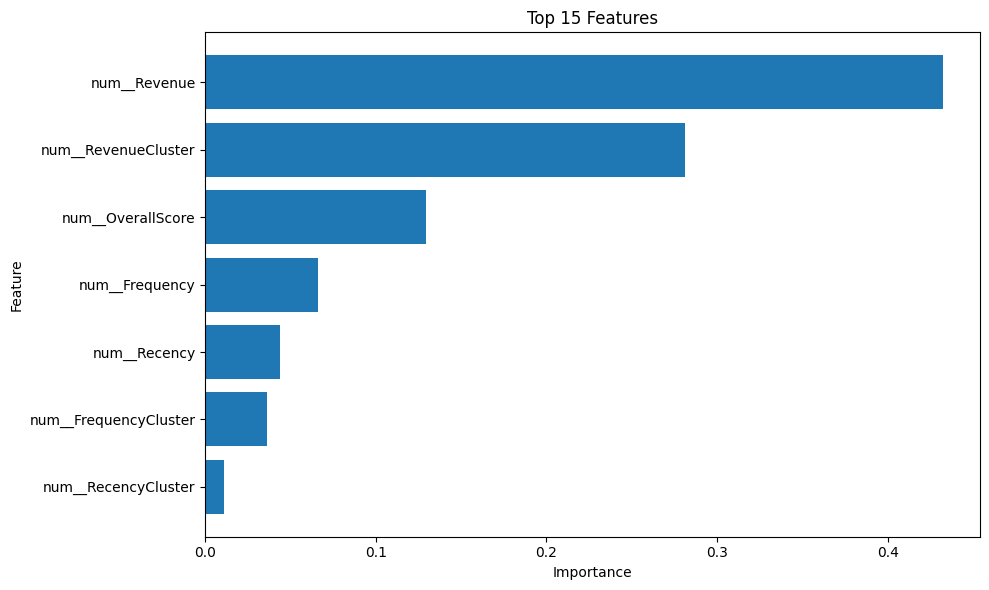

In [41]:

import matplotlib.pyplot as plt

plot_data = fi_df.head(15).sort_values(
    "Importance",
    ascending=True
)

if plot_data.empty:
    print("No feature importance values are available.")
else:
    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_data["Feature"],
        plot_data["Importance"]
    )

    plt.title("Top 15 Features")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


In [42]:

import joblib

model_path = "best_ltv_model.pkl"

joblib.dump(best_model, model_path)

print(f"Final model saved to: {model_path}")


Final model saved to: best_ltv_model.pkl


In [43]:

loaded_model = joblib.load(model_path)

original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

if np.array_equal(original_predictions, loaded_predictions):
    print("Model loading test passed.")
else:
    raise AssertionError(
        "Loaded model predictions do not match the original model."
    )


Model loading test passed.


In [44]:


def predict_high_value_customer(customer_dict, model, threshold=0.5):
    """
    Predict whether a customer belongs to the high-value group.
    Returns the predicted class and its probability.
    """

    if not 0 < threshold < 1:
        raise ValueError("Threshold must be between 0 and 1.")

    if not isinstance(customer_dict, dict):
        raise TypeError("Customer data must be provided as a dictionary.")

    required_features = list(X_train.columns)

    missing_features = [
        feature for feature in required_features
        if feature not in customer_dict
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    customer_df = pd.DataFrame(
        [{feature: customer_dict[feature] for feature in required_features}]
    )

    customer_df = customer_df.apply(
        pd.to_numeric,
        errors="raise"
    )

    if customer_df.isna().any().any():
        raise ValueError("Customer data contains missing values.")

    if not np.isfinite(customer_df.to_numpy()).all():
        raise ValueError("Customer data contains invalid numeric values.")

    probability = model.predict_proba(customer_df)[0, 1]
    prediction = int(probability >= threshold)

    return {
        "HighValuePrediction": prediction,
        "Probability": round(float(probability), 4),
        "Threshold": threshold
    }
